# BrandPulse AI — Sentiment Analysis on Twitter Data
## Notebook 1: Preprocessing & Classical NLP (TF-IDF + Logistic Regression / Naive Bayes)

**Goal (Week 1):** Clean the noise — load raw tweets, strip URLs/mentions/hashtags,
lemmatize, and inspect word frequency by class.

**Goal (Week 2):** Establish a baseline — TF-IDF vectorization, train Logistic
Regression and Naive Bayes, evaluate performance.

In [1]:
import re
import string
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)

import joblib
import json

pd.set_option("display.max_colwidth", 120)
RANDOM_STATE = 42

## 1. Load the Data

Dataset: `twitter_sentiment_data.csv` — 5,400 tweets labeled Positive / Negative / Neutral.
(See `data/generate_data.py` for the data-source note: this sandbox cannot reach
Kaggle/Sentiment140 directly, so a large template-driven synthetic tweet corpus with
realistic noise — URLs, @mentions, hashtags, RT markers, elongated words — was generated.
Drop in the real Sentiment140 / Twitter US Airline Sentiment CSV here with no other
code changes needed.)

In [2]:
df = pd.read_csv("data/twitter_sentiment_data.csv")
print(df.shape)
df.head(10)

(6300, 3)


,text,sentiment,created_at
0,"I waited 4 hours just to get my baggage handling sorted with @BrandPulseAir, ridiculous",negative,2026-07-12 12:00:00
1,"I'm so impressed with @CloudCarrier, their delivery exceeded my expectations ❤️ http://t.co/hfb1h1cb",positive,2026-07-12 12:00:00
2,"RT @BrandPulseAir customer support just solved my problem in 2 mins, incredible ❤️ http://t.co/1hbdhhde",positive,2026-07-12 12:00:00
3,"@CloudCarrier's baggage handling was okay I guess, nothing special either way http://t.co/525f55f2",neutral,2026-07-12 12:00:00
4,"I'm so impressed with @JetNow, their checkin process exceeded my expectations !!",positive,2026-07-12 12:01:00
5,reminder: @CloudCarrier seat check-in opens 24 hours before departure #brand,neutral,2026-07-12 12:01:00
6,RT Huge shoutout to @CloudCarrier for fixing my website issue so fast!! 😍 #CustomerService,positive,2026-07-12 12:01:00
7,"RT I waited 4 hours just to get my support team sorted with @FlyNova, ridiculous http://t.co/15123fbh #customerexper...",negative,2026-07-12 12:01:00
8,RT does anyone know if @SkyLineAir's in-flight wifi is working today? checking status http://t.co/2bh4abaf,positive,2026-07-12 12:01:00
9,@BrandPulseAir released a statement regarding app maintenance schedule #customerexperience @user166,neutral,2026-07-12 12:01:00


In [3]:
df["sentiment"].value_counts()

sentiment
negative    2580
positive    2094
neutral     1626
Name: count, dtype: int64

## 2. Preprocessing Pipeline — "Cleaning the Noise"

Tweets are some of the messiest text data around. Our pipeline:
1. Lowercase everything (**Normalization**)
2. Strip URLs, `@mentions`, and `#hashtags` with Regex (**Noise Removal**)
3. Remove punctuation, numbers, and RT markers
4. Tokenize, remove stopwords, and **Lemmatize** (e.g. "running" -> "run")

In [4]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

URL_RE = re.compile(r"http\S+|www\S+")
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#\w+")
RT_RE = re.compile(r"^rt\b", flags=re.IGNORECASE)
NON_ALPHA_RE = re.compile(r"[^a-zA-Z\s]")
REPEAT_CHAR_RE = re.compile(r"(.)\1{2,}")  # e.g. "sooooo" -> "soo"

def clean_tweet(text: str) -> str:
    text = str(text).lower()
    text = RT_RE.sub("", text)
    text = URL_RE.sub("", text)
    text = MENTION_RE.sub("", text)
    text = HASHTAG_RE.sub("", text)
    text = REPEAT_CHAR_RE.sub(r"\1\1", text)   # normalize elongated words
    text = NON_ALPHA_RE.sub(" ", text)         # strip punctuation/emojis/numbers
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize_lemmatize(text: str) -> str:
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 1]
    return " ".join(tokens)

df["clean_text"] = df["text"].apply(clean_tweet).apply(tokenize_lemmatize)
df[["text", "clean_text", "sentiment"]].head(10)

,text,clean_text,sentiment
0,"I waited 4 hours just to get my baggage handling sorted with @BrandPulseAir, ridiculous",waited hour get baggage handling sorted ridiculous,negative
1,"I'm so impressed with @CloudCarrier, their delivery exceeded my expectations ❤️ http://t.co/hfb1h1cb",impressed delivery exceeded expectation,positive
2,"RT @BrandPulseAir customer support just solved my problem in 2 mins, incredible ❤️ http://t.co/1hbdhhde",customer support solved problem min incredible,positive
3,"@CloudCarrier's baggage handling was okay I guess, nothing special either way http://t.co/525f55f2",baggage handling okay guess nothing special either way,neutral
4,"I'm so impressed with @JetNow, their checkin process exceeded my expectations !!",impressed checkin process exceeded expectation,positive
5,reminder: @CloudCarrier seat check-in opens 24 hours before departure #brand,reminder seat check open hour departure,neutral
6,RT Huge shoutout to @CloudCarrier for fixing my website issue so fast!! 😍 #CustomerService,huge shoutout fixing website issue fast,positive
7,"RT I waited 4 hours just to get my support team sorted with @FlyNova, ridiculous http://t.co/15123fbh #customerexper...",waited hour get support team sorted ridiculous,negative
8,RT does anyone know if @SkyLineAir's in-flight wifi is working today? checking status http://t.co/2bh4abaf,anyone know flight wifi working today checking status,positive
9,@BrandPulseAir released a statement regarding app maintenance schedule #customerexperience @user166,released statement regarding app maintenance schedule,neutral


## 3. Word Frequency Analysis (WordCloud) — Positive vs. Negative

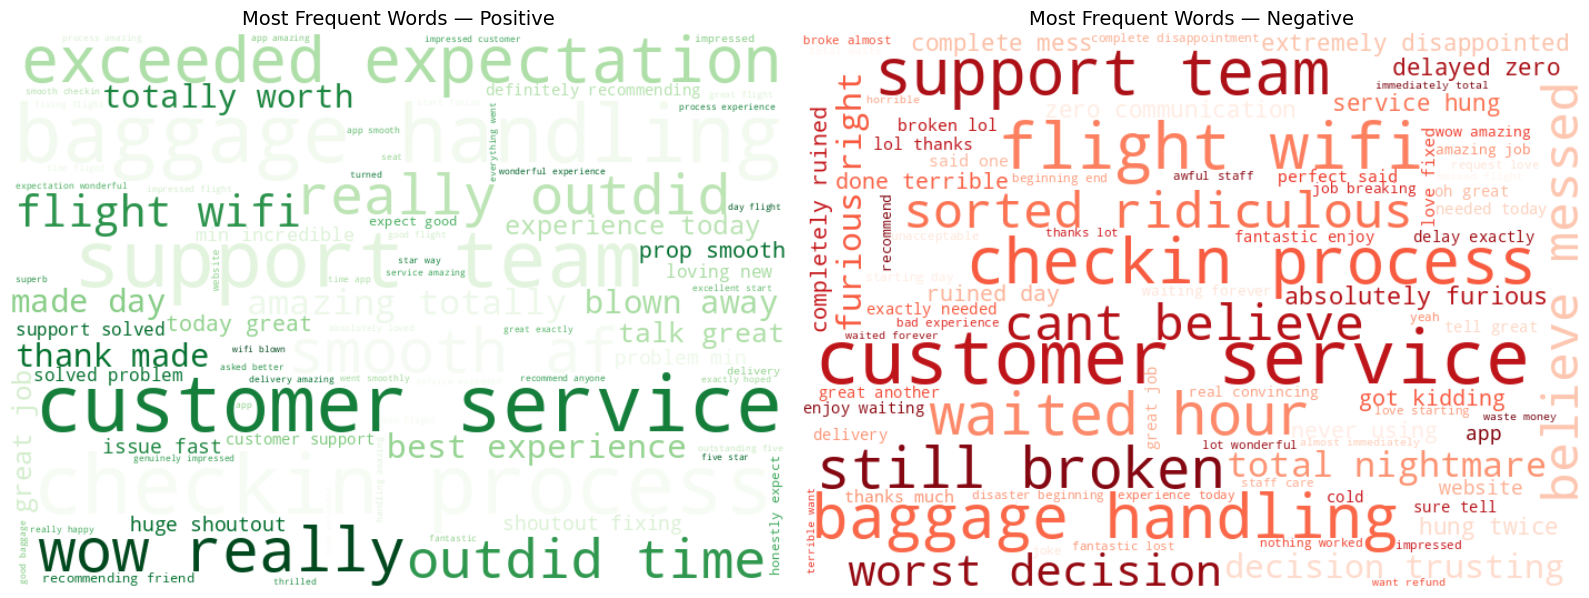

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, label, cmap in zip(axes, ["positive", "negative"], ["Greens", "Reds"]):
    text_blob = " ".join(df.loc[df["sentiment"] == label, "clean_text"])
    wc = WordCloud(width=700, height=500, background_color="white",
                   colormap=cmap, max_words=80).generate(text_blob)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"Most Frequent Words — {label.capitalize()}", fontsize=14)
    ax.axis("off")
plt.tight_layout()
plt.savefig("reports/wordcloud_pos_neg.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Train / Test Split

In [6]:
X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 5040 | Test size: 1260


## 5. Vectorization — TF-IDF (Term Frequency–Inverse Document Frequency)

TF–IDF converts text into numerical vectors by weighting words that are
frequent in a document but rare across the corpus — highlighting keywords
that are specific to that document.

In [7]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("TF-IDF matrix shape (train):", X_train_tfidf.shape)

TF-IDF matrix shape (train): (5040, 1370)


## 6. Train Classical Models — Logistic Regression, Naive Bayes, SVM

These models are fast and interpretable — a strong baseline before we move
to deep learning in Notebook 2.

In [8]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE),
}

results = {}
trained_models = {}

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    preds = model.predict(X_test_tfidf)
    acc = accuracy_score(y_test, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test, preds, average="weighted", zero_division=0
    )
    results[name] = {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}
    trained_models[name] = model
    print(f"\n=== {name} ===")
    print(classification_report(y_test, preds, zero_division=0))


=== Logistic Regression ===
              precision    recall  f1-score   support

    negative       0.97      0.97      0.97       516
     neutral       0.96      0.95      0.96       325
    positive       0.96      0.96      0.96       419

    accuracy                           0.96      1260
   macro avg       0.96      0.96      0.96      1260
weighted avg       0.96      0.96      0.96      1260


=== Naive Bayes ===
              precision    recall  f1-score   support

    negative       0.97      0.97      0.97       516
     neutral       0.96      0.95      0.96       325
    positive       0.96      0.96      0.96       419

    accuracy                           0.96      1260
   macro avg       0.96      0.96      0.96      1260
weighted avg       0.96      0.96      0.96      1260




=== Linear SVM ===
              precision    recall  f1-score   support

    negative       0.97      0.97      0.97       516
     neutral       0.96      0.95      0.96       325
    positive       0.96      0.96      0.96       419

    accuracy                           0.96      1260
   macro avg       0.96      0.96      0.96      1260
weighted avg       0.96      0.96      0.96      1260



## 7. Compare Classical Models

In [9]:
results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)
results_df.round(4)

,accuracy,precision,recall,f1
Logistic Regression,0.9643,0.9643,0.9643,0.9643
Naive Bayes,0.9643,0.9643,0.9643,0.9643
Linear SVM,0.9643,0.9643,0.9643,0.9643


**Best classical model** is selected automatically below and saved as the
"Approach A: Classical NLP" baseline for the final comparison report.

Best classical model:

 Logistic Regression


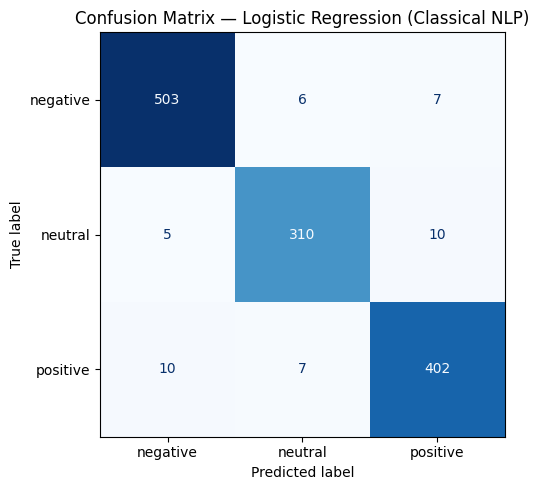

In [10]:
best_classical_name = results_df.index[0]
best_classical_model = trained_models[best_classical_name]
print("Best classical model:", best_classical_name)

preds_best = best_classical_model.predict(X_test_tfidf)
cm = confusion_matrix(y_test, preds_best, labels=sorted(y.unique()))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=sorted(y.unique()))
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion Matrix — {best_classical_name} (Classical NLP)")
plt.tight_layout()
plt.savefig("reports/confusion_matrix_classical.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Save Model + Vectorizer (for the Streamlit Dashboard)

In [11]:
joblib.dump(best_classical_model, "models/classical_model.joblib")
joblib.dump(tfidf, "models/tfidf_vectorizer.joblib")

with open("models/classical_metrics.json", "w") as f:
    json.dump({
        "best_model_name": best_classical_name,
        "all_results": results,
    }, f, indent=2)

print("Saved classical model, vectorizer, and metrics.")
results_df.round(4)

Saved classical model, vectorizer, and metrics.


,accuracy,precision,recall,f1
Logistic Regression,0.9643,0.9643,0.9643,0.9643
Naive Bayes,0.9643,0.9643,0.9643,0.9643
Linear SVM,0.9643,0.9643,0.9643,0.9643
